# XGBoost para clasificar anemia infantil

En este notebook entrenamos XGBoost, el tercer modelo del trabajo final. Para poder compararlo con la regresión logística y el Random Forest usamos exactamente lo mismo: el dataset de 99 472 niños (ENDES 2020–2025), los 25 predictores y la misma división 80/20 con `random_state=42`.

Primero probamos el modelo con sus valores por defecto y luego buscamos mejores hiperparámetros con validación cruzada. Después lo evaluamos en el conjunto de prueba, vemos qué pasa si cambiamos el umbral de decisión y usamos SHAP para entender qué variables pesan más en sus predicciones. Al final comprobamos si con solo 10 variables se obtiene un resultado parecido al de las 25.

## 1. Carga y división de datos

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

SEMILLA = 42
CARPETA_RESULTADOS = Path("resultados_xgboost")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

dataset = pd.read_csv("DATASET_LIMPIO_ANEMIA.csv")
print(f"Registros: {len(dataset):,} | Columnas: {dataset.shape[1]}")

Registros: 99,472 | Columnas: 26


In [2]:
variables_numericas = [
    "edad_meses", "peso_nino_kg", "talla_nino_cm", "z_talla_edad", "z_peso_edad",
    "z_peso_talla", "z_imc_edad", "edad_madre", "anios_educacion_madre",
    "altitud_residencia_m", "peso_madre_kg", "peso_nacer_kg", "talla_madre_m",
]
variables_categoricas = [
    "anemia_materna_embarazo", "desparasitacion", "diarrea_reciente", "fiebre_reciente",
    "nivel_educativo_madre", "quintil_riqueza", "area_residencia", "sexo_nino",
    "anemia_materna_actual", "nivel_pobreza", "anio_encuesta", "departamento",
]

X = dataset.drop(columns=["ANEMIA"])
y = dataset["ANEMIA"]
assert set(variables_numericas + variables_categoricas) == set(X.columns)

# Misma división que el notebook de Regresión Logística
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)

conteo = y_train.value_counts()
peso_positivos = conteo[0] / conteo[1]
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}")
print(f"Proporción de anemia en entrenamiento: {y_train.mean():.3f}")
print(f"scale_pos_weight (sin anemia / con anemia): {peso_positivos:.3f}")

Entrenamiento: 79,577 | Prueba: 19,895
Proporción de anemia en entrenamiento: 0.339
scale_pos_weight (sin anemia / con anemia): 1.951


Dos decisiones antes de entrenar:

- **No escalamos las variables numéricas.** XGBoost trabaja con árboles, que solo comparan valores contra umbrales, así que la escala no le afecta. Las variables categóricas sí las pasamos a one-hot. Todo va dentro de un pipeline para que el encoder aprenda solo con los datos de entrenamiento.
- **El desbalance lo manejamos con pesos, no eliminando filas.** Hay casi el doble de niños sin anemia que con anemia, así que usamos `scale_pos_weight` ≈ 1,95. Con esto, cada caso con anemia pesa casi el doble durante el entrenamiento. Es lo mismo que hace `class_weight="balanced"` en la regresión logística.

In [3]:
def crear_preprocesador(numericas, categoricas):
    return ColumnTransformer(
        [
            ("num", "passthrough", numericas),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
        ],
        verbose_feature_names_out=False,
    )


def crear_modelo(numericas, categoricas, **parametros):
    xgb = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=peso_positivos,
        random_state=SEMILLA,
        n_jobs=-1,
        **parametros,
    )
    return Pipeline([
        ("preprocesador", crear_preprocesador(numericas, categoricas)),
        ("xgb", xgb),
    ])


def calcular_metricas(y_real, probabilidad, umbral=0.5):
    prediccion = (probabilidad >= umbral).astype(int)
    return {
        "Accuracy": accuracy_score(y_real, prediccion),
        "Precision": precision_score(y_real, prediccion, zero_division=0),
        "Recall": recall_score(y_real, prediccion),
        "F1-score": f1_score(y_real, prediccion),
        "ROC-AUC": roc_auc_score(y_real, probabilidad),
        "PR-AUC": average_precision_score(y_real, probabilidad),
    }

## 2. Modelo base

Antes de ajustar nada, vemos cómo le va a XGBoost con sus hiperparámetros por defecto. Lo evaluamos con validación cruzada de 5 particiones sobre el conjunto de entrenamiento. Este resultado nos sirve de punto de partida para saber si la búsqueda de hiperparámetros realmente mejora algo.

In [4]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision",
}

modelo_base = crear_modelo(variables_numericas, variables_categoricas)
cv_base = cross_validate(modelo_base, X_train, y_train, cv=validacion, scoring=metricas_cv, n_jobs=1)

resumen_cv_base = pd.DataFrame({
    "Media": {k.replace("test_", ""): v.mean() for k, v in cv_base.items() if k.startswith("test_")},
    "Desv. estándar": {k.replace("test_", ""): v.std() for k, v in cv_base.items() if k.startswith("test_")},
})
display(resumen_cv_base.round(4))

,Media,Desv. estándar
accuracy,0.6936,0.0022
precision,0.5400,0.0028
recall,0.6460,0.0047
f1,0.5882,0.0030
roc_auc,0.7428,0.0015
average_precision,0.5954,0.0052


## 3. Búsqueda de hiperparámetros

XGBoost tiene muchos hiperparámetros (número de árboles, profundidad, tasa de aprendizaje, etc.) y probar todas las combinaciones tomaría demasiado tiempo. Por eso usamos `RandomizedSearchCV`, que prueba 25 combinaciones al azar, cada una con validación cruzada de 5 particiones, y se queda con la de mayor ROC-AUC promedio.

Elegimos ROC-AUC como criterio porque no depende del umbral de decisión. El Recall, que es la métrica que más nos interesa, lo revisamos aparte en la sección 5.

In [5]:
espacio_busqueda = {
    "xgb__n_estimators": randint(150, 701),
    "xgb__max_depth": randint(3, 9),
    "xgb__learning_rate": loguniform(0.02, 0.2),
    "xgb__subsample": uniform(0.6, 0.4),
    "xgb__colsample_bytree": uniform(0.5, 0.5),
    "xgb__min_child_weight": randint(1, 11),
    "xgb__gamma": uniform(0, 2),
    "xgb__reg_lambda": loguniform(0.5, 10),
}

busqueda = RandomizedSearchCV(
    crear_modelo(variables_numericas, variables_categoricas),
    param_distributions=espacio_busqueda,
    n_iter=25,
    scoring="roc_auc",
    cv=validacion,
    random_state=SEMILLA,
    n_jobs=1,
    refit=True,
)

inicio = time.time()
busqueda.fit(X_train, y_train)
print(f"Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} min")
print(f"Mejor ROC-AUC en validación cruzada: {busqueda.best_score_:.4f}")
print(f"ROC-AUC del modelo base en validación cruzada: {cv_base['test_roc_auc'].mean():.4f}")

mejores_parametros = {k.replace("xgb__", ""): v for k, v in busqueda.best_params_.items()}
display(pd.Series(mejores_parametros, name="Valor").to_frame())

Tiempo de búsqueda: 3.4 min
Mejor ROC-AUC en validación cruzada: 0.7584
ROC-AUC del modelo base en validación cruzada: 0.7428


,Valor
colsample_bytree,0.776447
gamma,1.185393
learning_rate,0.024093
max_depth,5.000000
min_child_weight,1.000000
n_estimators,443.000000
reg_lambda,1.504759
subsample,0.852922


In [6]:
# Las 5 mejores combinaciones de la búsqueda
top_busqueda = (
    pd.DataFrame(busqueda.cv_results_)
    .sort_values("rank_test_score")
    .loc[:, ["rank_test_score", "mean_test_score", "std_test_score"]
         + [c for c in busqueda.cv_results_ if c.startswith("param_")]]
    .head(5)
)
top_busqueda.columns = [c.replace("param_xgb__", "") for c in top_busqueda.columns]
display(top_busqueda.round(4))

,rank_test_score,mean_test_score,std_test_score,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample
21,1,0.7584,0.0015,0.7764,1.1854,0.0241,5,1,443,1.5048,0.8529
23,2,0.7584,0.0012,0.9292,0.6519,0.0332,4,3,660,0.9855,0.8581
4,3,0.7581,0.0014,0.8038,0.3410,0.0232,6,9,465,2.7029,0.7542
20,4,0.7581,0.0014,0.7055,0.0661,0.0443,3,3,279,2.4532,0.7791
15,5,0.7579,0.0012,0.5806,1.8594,0.1286,3,5,177,0.9620,0.7666


## 4. Evaluación en prueba

Con los mejores hiperparámetros, el modelo se vuelve a entrenar con todo el conjunto de entrenamiento y se evalúa **una sola vez** en el 20 % de prueba, que no se usó en ningún paso anterior. Usamos el umbral 0,5.

In [7]:
modelo_final = busqueda.best_estimator_
probabilidad_test = modelo_final.predict_proba(X_test)[:, 1]
prediccion_test = (probabilidad_test >= 0.5).astype(int)

metricas_test = pd.Series(calcular_metricas(y_test, probabilidad_test), name="XGBoost (prueba)")
display(metricas_test.round(4).to_frame())

,XGBoost (prueba)
Accuracy,0.7000
Precision,0.5462
Recall,0.6783
F1-score,0.6051
ROC-AUC,0.7595
PR-AUC,0.6201


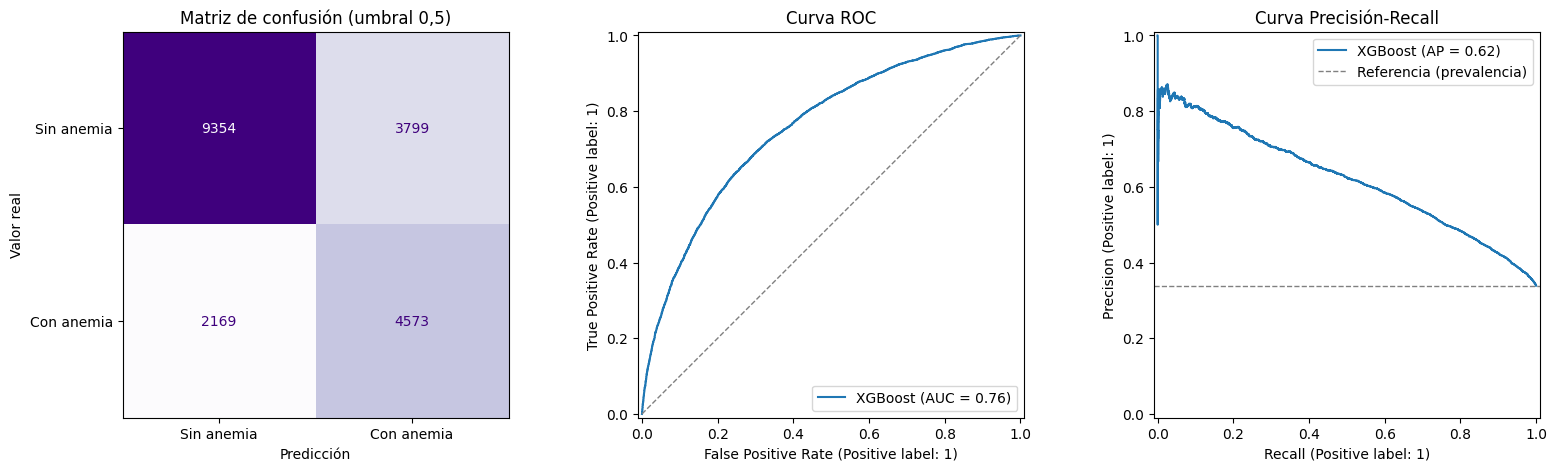

Casos con anemia detectados: 4,573 de 6,742 (67.8%).
Falsos negativos: 2,169 | Falsos positivos: 3,799


In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")

matriz = confusion_matrix(y_test, prediccion_test, labels=[0, 1])
ConfusionMatrixDisplay(matriz, display_labels=["Sin anemia", "Con anemia"]).plot(
    ax=ejes[0], cmap="Purples", colorbar=False, values_format="d"
)
ejes[0].set(title="Matriz de confusión (umbral 0,5)", xlabel="Predicción", ylabel="Valor real")

RocCurveDisplay.from_predictions(y_test, probabilidad_test, ax=ejes[1], name="XGBoost")
ejes[1].plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
ejes[1].set(title="Curva ROC")

PrecisionRecallDisplay.from_predictions(y_test, probabilidad_test, ax=ejes[2], name="XGBoost")
ejes[2].axhline(y_test.mean(), linestyle="--", color="grey", linewidth=1, label="Referencia (prevalencia)")
ejes[2].set(title="Curva Precisión-Recall")
ejes[2].legend(loc="upper right")

fig.savefig(CARPETA_RESULTADOS / "evaluacion_xgboost.png", dpi=150)
plt.show()

vn, fp, fn, vp = matriz.ravel()
print(f"Casos con anemia detectados: {vp:,} de {vp + fn:,} ({vp / (vp + fn):.1%}).")
print(f"Falsos negativos: {fn:,} | Falsos positivos: {fp:,}")

## 5. ¿Qué pasa si cambiamos el umbral?

Por defecto, el modelo dice "con anemia" cuando la probabilidad es 0,5 o más, pero ese valor no es obligatorio. Si lo bajamos, el modelo detecta más niños con anemia (sube el Recall), a cambio de dar más falsas alarmas (baja la Precisión). Como en este problema es peor no detectar un caso que dar una falsa alarma, vale la pena ver ese equilibrio. En la comparación principal seguimos reportando el umbral 0,5.

In [9]:
umbrales = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
tabla_umbrales = pd.DataFrame(
    {u: calcular_metricas(y_test, probabilidad_test, u) for u in umbrales}
).T.drop(columns=["ROC-AUC", "PR-AUC"])
tabla_umbrales.index.name = "Umbral"
display(tabla_umbrales.round(4))

,Accuracy,Precision,Recall,F1-score
Umbral,,,,
0.30,0.5645,0.4309,0.8891,0.5805
0.35,0.6137,0.4615,0.8401,0.5958
0.40,0.6502,0.4899,0.7870,0.6039
0.45,0.6782,0.5177,0.7338,0.6071
0.50,0.7000,0.5462,0.6783,0.6051
0.55,0.7179,0.5786,0.6167,0.5971
0.60,0.7258,0.6058,0.5466,0.5747


## 6. ¿Qué variables usa el modelo? (SHAP)

Para entender en qué se basa el modelo usamos SHAP con `TreeExplainer`, que está hecho para modelos de árboles. Calculamos los valores para una muestra de 3 000 niños de prueba.

Un detalle: como las variables categóricas se convirtieron en varias columnas (por ejemplo, una por cada departamento), sumamos sus valores SHAP para tener una sola importancia por variable. Así se puede comparar con lo que salga en la regresión logística y el Random Forest.

Hay que tener en cuenta que SHAP muestra qué variables usa el modelo para predecir, no qué causa la anemia.

In [10]:
preprocesador = modelo_final.named_steps["preprocesador"]
xgb_final = modelo_final.named_steps["xgb"]
nombres_columnas = preprocesador.get_feature_names_out()


def variable_original(columna):
    if columna in variables_numericas:
        return columna
    for variable in sorted(variables_categoricas, key=len, reverse=True):
        if columna.startswith(variable + "_"):
            return variable
    return columna


mapa_variables = pd.Series([variable_original(c) for c in nombres_columnas], index=nombres_columnas)

muestra_test = X_test.sample(3000, random_state=SEMILLA)
X_muestra = pd.DataFrame(preprocesador.transform(muestra_test), columns=nombres_columnas, index=muestra_test.index)

explicador = shap.TreeExplainer(xgb_final)
valores_shap = explicador(X_muestra)

# Suma de los valores SHAP de las columnas one-hot de cada variable original
shap_por_variable = (
    pd.DataFrame(valores_shap.values, columns=nombres_columnas)
    .T.groupby(mapa_variables).sum().T
)
importancia_shap = (
    shap_por_variable.abs().mean()
    .sort_values(ascending=False)
    .rename("Media |SHAP|")
)
importancia_shap_pct = (importancia_shap / importancia_shap.sum() * 100).rename("% del total")
tabla_importancia = pd.concat([importancia_shap, importancia_shap_pct], axis=1)
display(tabla_importancia.round(4))

,Media |SHAP|,% del total
talla_nino_cm,0.4764,23.597799
altitud_residencia_m,0.2598,12.866400
anemia_materna_actual,0.1795,8.888200
edad_meses,0.1667,8.258900
departamento,0.1202,5.955500
quintil_riqueza,0.1076,5.330800
sexo_nino,0.1032,5.112800
anios_educacion_madre,0.0743,3.678000
anemia_materna_embarazo,0.0706,3.497900
peso_nino_kg,0.0650,3.219800


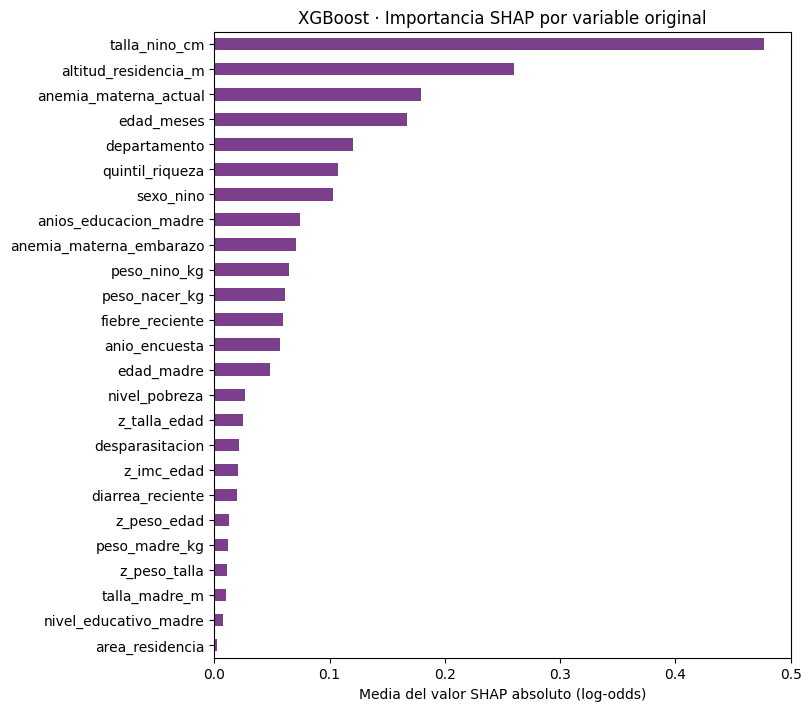

In [11]:
fig, eje = plt.subplots(figsize=(8, 7), layout="constrained")
importancia_shap.sort_values().plot.barh(ax=eje, color="#7b3f8c")
eje.set(
    title="XGBoost · Importancia SHAP por variable original",
    xlabel="Media del valor SHAP absoluto (log-odds)", ylabel="",
)
fig.savefig(CARPETA_RESULTADOS / "shap_importancia_xgboost.png", dpi=150)
plt.show()

**Gráfico beeswarm.** Cada punto es un niño. El color indica si el valor de la variable es alto (rojo) o bajo (azul), y la posición indica hacia dónde empuja la predicción: a la derecha hacia "con anemia" y a la izquierda hacia "sin anemia". Aquí las categorías aparecen por separado (por ejemplo, `quintil_riqueza_1`).

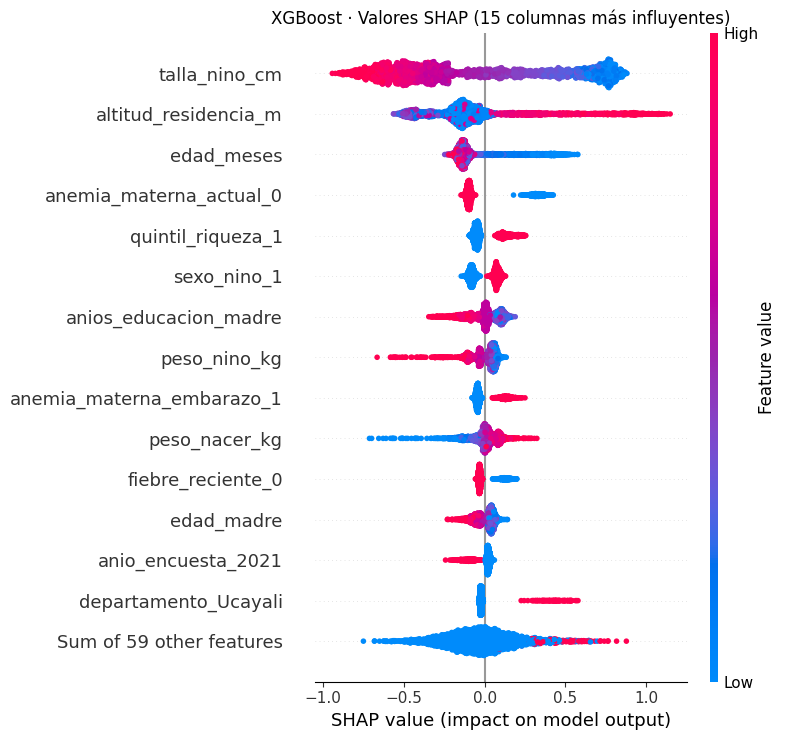

In [12]:
plt.figure()
shap.plots.beeswarm(valores_shap, max_display=15, show=False)
plt.title("XGBoost · Valores SHAP (15 columnas más influyentes)")
plt.tight_layout()
plt.savefig(CARPETA_RESULTADOS / "shap_beeswarm_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

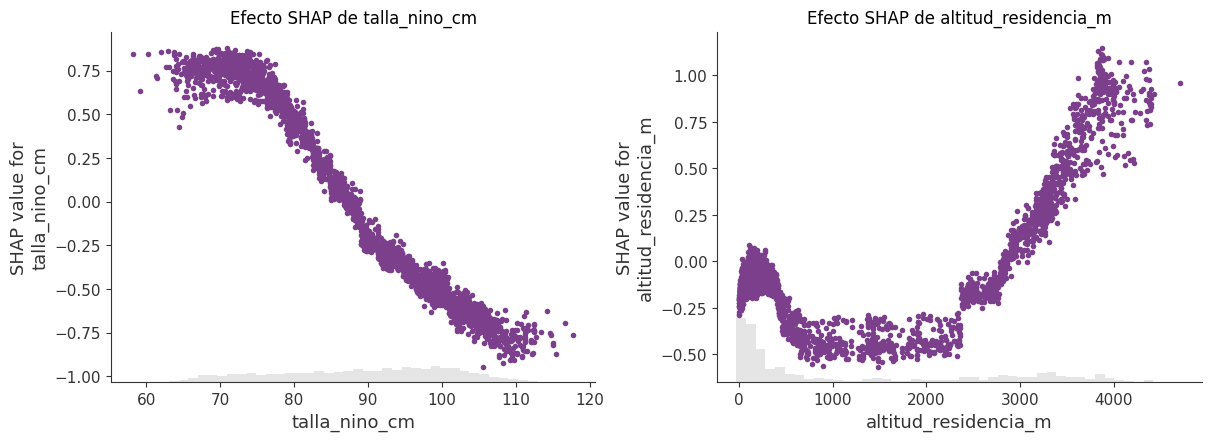

In [13]:
# Efecto de las dos variables más importantes
principales = [v for v in importancia_shap.index if v in variables_numericas][:2]
fig, ejes = plt.subplots(1, len(principales), figsize=(12, 4.3), layout="constrained")
for eje, variable in zip(np.atleast_1d(ejes), principales):
    shap.plots.scatter(valores_shap[:, variable], ax=eje, show=False, color="#7b3f8c")
    eje.set_title(f"Efecto SHAP de {variable}")
fig.savefig(CARPETA_RESULTADOS / "shap_dependencia_xgboost.png", dpi=150)
plt.show()

## 7. ¿Se puede usar menos variables?

Queremos saber si un modelo más simple funciona casi igual. Para eso tomamos las 10 variables más importantes según SHAP y entrenamos otro modelo solo con ellas, con los mismos hiperparámetros.

Para elegir esas 10 variables usamos SHAP calculado sobre datos de **entrenamiento**, no de prueba. Si usáramos el conjunto de prueba para elegirlas, la comparación quedaría sesgada a favor del modelo reducido.

In [14]:
muestra_train = X_train.sample(3000, random_state=SEMILLA)
X_muestra_train = pd.DataFrame(preprocesador.transform(muestra_train), columns=nombres_columnas)
shap_train = explicador(X_muestra_train)
importancia_train = (
    pd.DataFrame(shap_train.values, columns=nombres_columnas)
    .T.groupby(mapa_variables).sum().T
    .abs().mean().sort_values(ascending=False)
)

N_VARIABLES = 10
seleccionadas = list(importancia_train.index[:N_VARIABLES])
num_sel = [v for v in variables_numericas if v in seleccionadas]
cat_sel = [v for v in variables_categoricas if v in seleccionadas]
print("Variables seleccionadas:", ", ".join(seleccionadas))

modelo_reducido = crear_modelo(num_sel, cat_sel, **mejores_parametros)
modelo_reducido.fit(X_train[seleccionadas], y_train)
probabilidad_reducido = modelo_reducido.predict_proba(X_test[seleccionadas])[:, 1]

comparacion_variables = pd.DataFrame({
    f"Todas ({len(X.columns)} variables)": calcular_metricas(y_test, probabilidad_test),
    f"Seleccionadas ({N_VARIABLES} variables)": calcular_metricas(y_test, probabilidad_reducido),
})
comparacion_variables["Diferencia"] = comparacion_variables.iloc[:, 1] - comparacion_variables.iloc[:, 0]
display(comparacion_variables.round(4))

Variables seleccionadas: talla_nino_cm, altitud_residencia_m, anemia_materna_actual, edad_meses, departamento, quintil_riqueza, sexo_nino, anios_educacion_madre, anemia_materna_embarazo, peso_nino_kg


,Todas (25 variables),Seleccionadas (10 variables),Diferencia
Accuracy,0.7000,0.6978,-0.0023
Precision,0.5462,0.5434,-0.0028
Recall,0.6783,0.6772,-0.0010
F1-score,0.6051,0.6030,-0.0022
ROC-AUC,0.7595,0.7553,-0.0043
PR-AUC,0.6201,0.6160,-0.0041


## 8. Guardar resultados

Guardamos las métricas, la importancia SHAP, la tabla de umbrales y los hiperparámetros en `resultados_xgboost/`, para armar después la tabla comparativa con los otros dos modelos.

In [15]:
resultados = pd.DataFrame({
    "XGBoost base (CV 5)": resumen_cv_base["Media"].rename({
        "accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
        "f1": "F1-score", "roc_auc": "ROC-AUC", "average_precision": "PR-AUC",
    }),
    "XGBoost ajustado (prueba)": metricas_test,
    f"XGBoost {N_VARIABLES} variables (prueba)": comparacion_variables.iloc[:, 1],
})
display(resultados.round(4))

resultados.to_csv(CARPETA_RESULTADOS / "metricas_xgboost.csv")
tabla_importancia.to_csv(CARPETA_RESULTADOS / "importancia_shap_xgboost.csv")
tabla_umbrales.to_csv(CARPETA_RESULTADOS / "umbrales_xgboost.csv")
pd.Series(mejores_parametros).to_csv(CARPETA_RESULTADOS / "hiperparametros_xgboost.csv", header=["valor"])
print("Archivos guardados en", CARPETA_RESULTADOS.resolve())

,XGBoost base (CV 5),XGBoost ajustado (prueba),XGBoost 10 variables (prueba)
Accuracy,0.6936,0.7000,0.6978
Precision,0.5400,0.5462,0.5434
Recall,0.6460,0.6783,0.6772
F1-score,0.5882,0.6051,0.6030
ROC-AUC,0.7428,0.7595,0.7553
PR-AUC,0.5954,0.6201,0.6160


Archivos guardados en E:\USIL\Agentes Inteligentes\hemora-endes\resultados_xgboost


## Resumen

- **Rendimiento.** En el conjunto de prueba, XGBoost obtuvo un ROC-AUC de 0,760 y un Recall de 0,678: detectó 4 573 de los 6 742 niños con anemia. La búsqueda de hiperparámetros mejoró el ROC-AUC de 0,743 (modelo base) a 0,758 en validación cruzada.
- **Comparado con la regresión logística** (ROC-AUC 0,752 con pesos balanceados), la mejora es pequeña. Esto coincide con otros estudios sobre anemia infantil, donde los modelos de árboles ganan poco frente a la regresión logística.
- **Umbral.** Si bajamos el umbral a 0,40, el modelo detecta el 79 % de los casos, pero la Precisión baja de 0,55 a 0,49.
- **Variables más importantes (SHAP).** Talla del niño, altitud, anemia de la madre, edad, departamento, quintil de riqueza y sexo. La talla y la edad están muy relacionadas entre sí, así que conviene interpretarlas juntas como el crecimiento del niño para su edad.
- **Modelo reducido.** Con 10 variables el ROC-AUC baja solo de 0,760 a 0,755, así que se puede simplificar el modelo casi sin perder rendimiento.